# Time-Series data and RNNs

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Sequential dataset: Sunspots

[Monthly mean total sunspot number](https://www.sidc.be/SILSO/infosnmtot)

In [3]:
df = pd.read_csv('~/data10/SN_m_tot_V2.0.csv', names=['Year', 'Month', 'date_frac', 'Sunspots', 'std', 'n_obs', 'definitive'], delimiter=';')
df['date'] = pd.to_datetime({'year': df['Year'], 'month': df['Month'], 'day':1})
df.head()

,Year,Month,date_frac,Sunspots,std,n_obs,definitive,date
0,1749,1,1749.042,96.7,-1.0,-1,1,1749-01-01
1,1749,2,1749.123,104.3,-1.0,-1,1,1749-02-01
2,1749,3,1749.204,116.7,-1.0,-1,1,1749-03-01
3,1749,4,1749.288,92.8,-1.0,-1,1,1749-04-01
4,1749,5,1749.371,141.7,-1.0,-1,1,1749-05-01


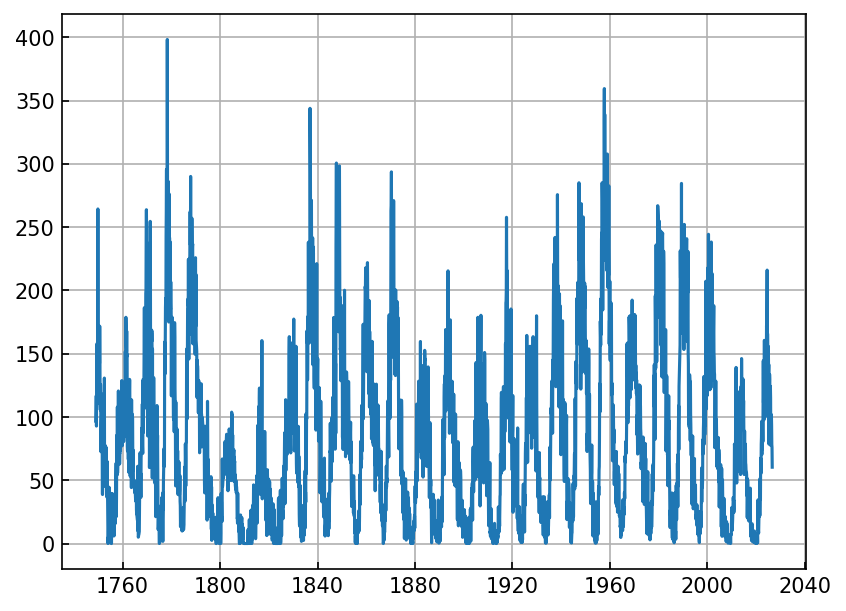

In [4]:
ax = plt.figure().gca()
ax.plot(df.date, df.Sunspots)

RNN Train Dataset has 2908 sequences
RNN Test Dataset has 375 sequences


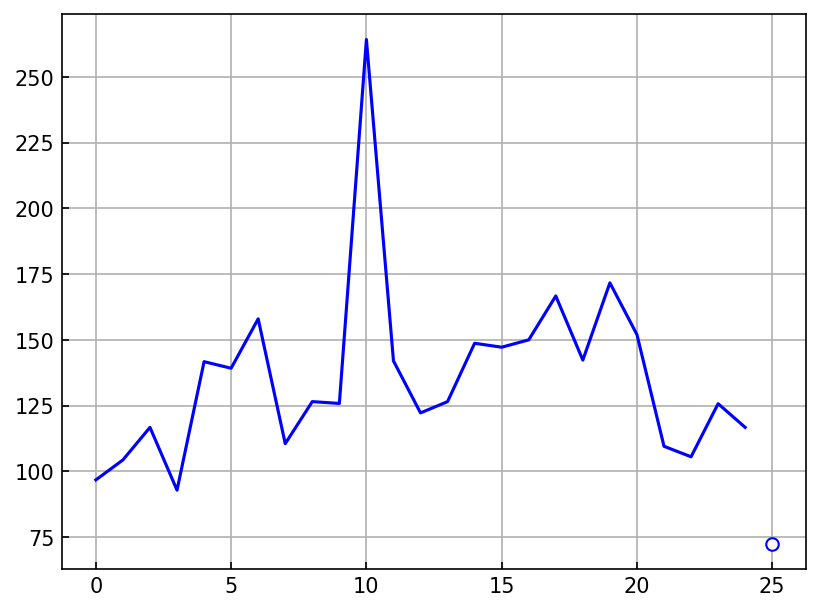

In [5]:
from torch.utils.data import Dataset

class SequenceDataset(Dataset):
    def __init__(self, df, seq_len=25, seq_stride=1):
        self.df = df
        self.seq_len = seq_len
        self.seq_stride = seq_stride

    def __len__(self):
        return len(self.df) - self.seq_len * self.seq_stride

    def __getitem__(self, idx):
        """ Return a sequence of length self.seq_len with stride self.seq_stride
            paired with the next element of the sequence
        """
        slc = slice(idx, idx + (self.seq_len + 1) * self.seq_stride, self.seq_stride)
        x = torch.FloatTensor(self.df['Sunspots'].values[slc, None])
        return x[:-1], x[-1] # For each element, predict the next element in the sequence

train_seqs = df.iloc[:-400]
test_seqs = df.iloc[-400:]

train_val_dataset = SequenceDataset(train_seqs)
print(f"RNN Train Dataset has {len(train_val_dataset)} sequences")

test_dataset = SequenceDataset(test_seqs)
print(f"RNN Test Dataset has {len(test_dataset)} sequences")

x, y = train_val_dataset[0]

ax = plt.figure().gca()
t = np.arange(len(x))
ax.plot(t, x[:, 0], color='blue')
ax.plot(t[-1] + 1, y[0], color='blue', marker='o', markerfacecolor='white')

## A simple baseline for time-series forecasting

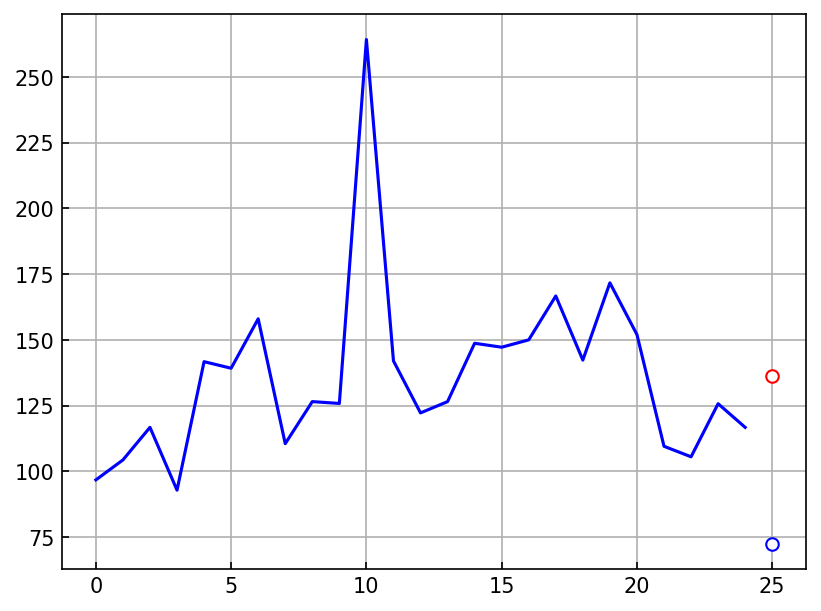

In [6]:
# Simple option - take the average of the lookback-window
x, y = train_val_dataset[0]

ax = plt.figure().gca()
t = np.arange(len(x))
ax.plot(t, x[:, 0], color='blue')
ax.plot(t[-1] + 1, y[0], color='blue', marker='o', markerfacecolor='white')

y_pred = x.mean(dim=0)
ax.plot(t[-1] + 1, y_pred, color='red', marker='o', markerfacecolor='white')

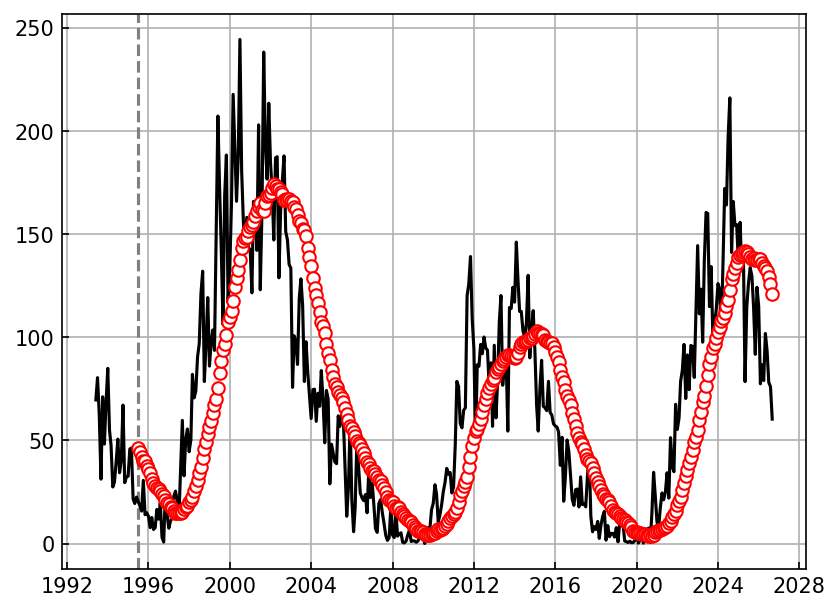

In [7]:
# Simple option - take the average of the lookback-window
# Iterate through the whole test dataset and see how it does
ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

tt = test_dataset.seq_len
for idx in range(len(test_dataset)):
    x, y, = test_dataset[idx]
    y_pred = x.mean(dim=0)
    ax.plot(test_dataset.df.date.iloc[tt], y_pred, color='red', marker='o', markerfacecolor='white')
    tt += 1

[Text(0, 0.5, 'Sunspots')]

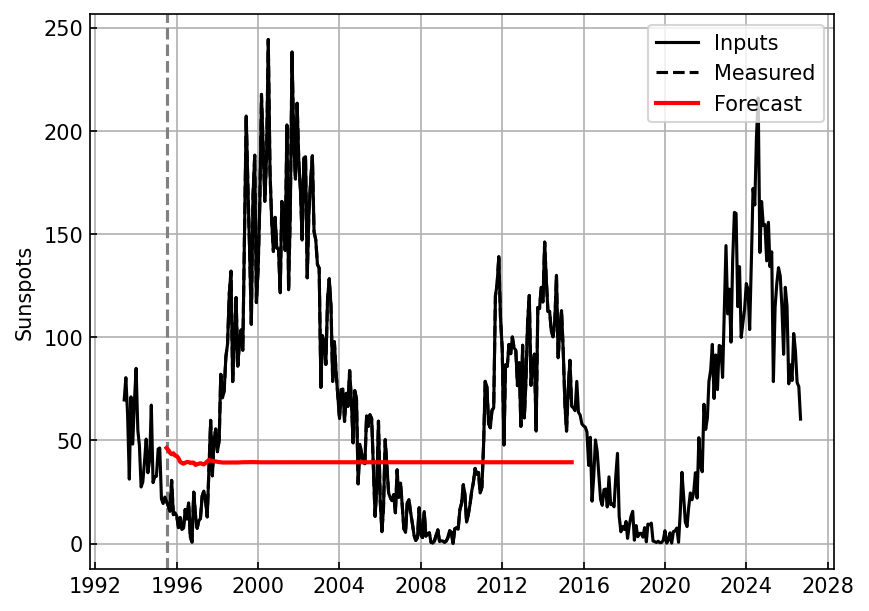

In [8]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]

# What if we want to forecast many months out?
forecast_len = 240

y_pred = []

with torch.no_grad():
    for ii in range(forecast_len):
        y_out = x_in.mean(dim=0)
        y_pred.append(y_out.numpy())
        x_in = torch.concat([x_in[1:], y_out[:, None]])
    y_pred = np.concatenate(y_pred)

ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_pred)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_pred)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_pred, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    ylabel='Sunspots'
)

## Another baseline (ARIMA)

278


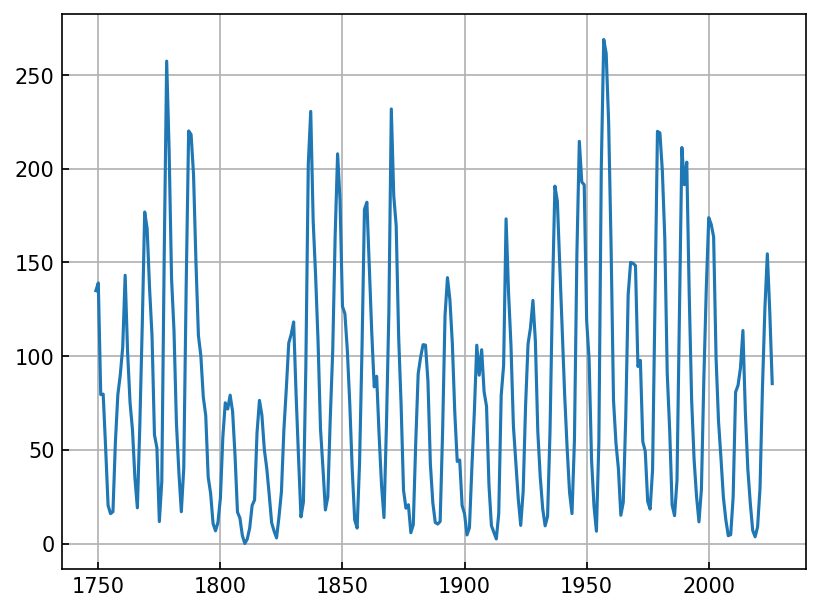

In [9]:
# Sum by year because otherwise this takes forever
year_df = df.groupby('Year').agg({'Sunspots': lambda x : x.mean()}).reset_index()
print(len(year_df))
ax = plt.figure().gca()
ax.plot(year_df.Year, year_df.Sunspots)

In [10]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.api import qqplot

forecast_years = 30
df_train = year_df.iloc[:-forecast_years]
df_test = year_df.iloc[-forecast_years:]

model = SARIMAX(df_train['Sunspots'], order=(3, 0, 0), trend="c").fit(disp=False)

[(1950.0, 2030.0), Text(0.5, 0, 'Year'), Text(0, 0.5, 'Sunspots')]

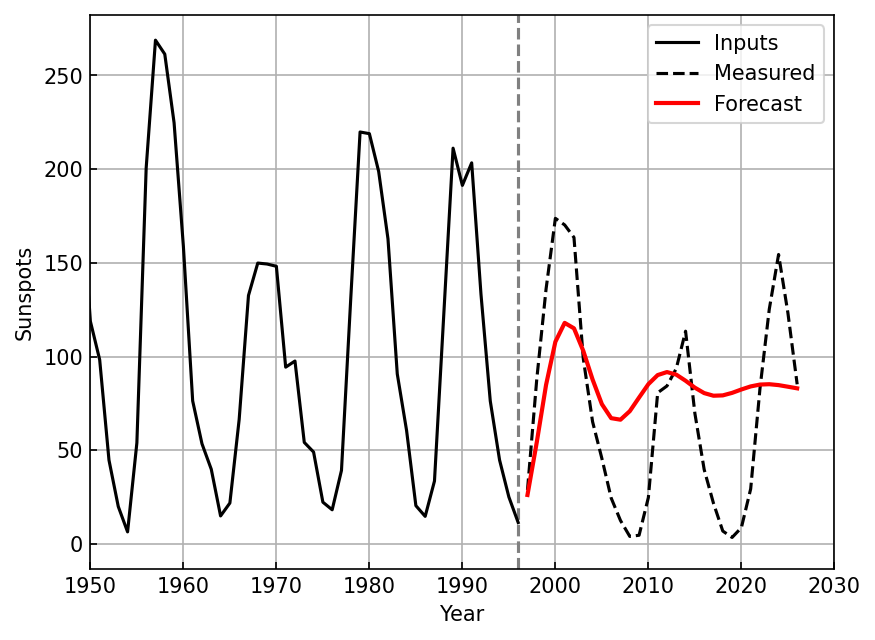

In [11]:
y_pred = model.forecast(steps=forecast_years).values

ax = plt.figure().gca()
ax.axvline(df_train.Year.iloc[-1], color='grey', linestyle='--')
ax.plot(df_train.Year, df_train.Sunspots, color='black', label='Inputs')

ax.plot(df_test.Year, df_test.Sunspots, color='black', linestyle='--', label='Measured')
ax.plot(df_test.Year, y_pred, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    xlim=[1950, 2030],
    xlabel='Year',
    ylabel='Sunspots'
)

## RNN Training

In [12]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm.notebook import trange, tqdm

def train(model, optimizer, loss_func, train_dataset, val_dataset, batch_size=64, num_epochs=10, num_workers=4):
    model = model.to(device)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    train_loss = []
    train_mad = []
    val_loss = []
    val_mad = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_mad_ = 0.
        for xb, yb in train_loader:
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb)
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_mad.append(train_mad_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_mad_ = 0.
            for xb, yb in val_loader:
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb)
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_mad_ += F.l1_loss(y_pred, yb, reduction='sum').item()
                
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_mad.append(val_mad_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_MAD=f"{train_mad[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_MAD=f"{val_mad[-1]:.3f}")
        # Consider early stopping
        # Consider learning rate scheduling

    return model, (train_loss, train_mad, val_loss, val_mad)

In [13]:
class RNN_Sequence_Forecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 128, num_layers=1, batch_first=True)
        self.linear = nn.Linear(128, 1)
        
    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)
        output = self.linear(output[:, -1])
        return output

from torch.utils.data import random_split
torch.manual_seed(42)
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])

rnn_model = RNN_Sequence_Forecast().to(device)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=1e-3)
rnn_model, rnn_stats = train(rnn_model, optimizer, loss, train_dataset, val_dataset, num_epochs=50)

  0%|          | 0/50 [00:00<?, ?it/s]

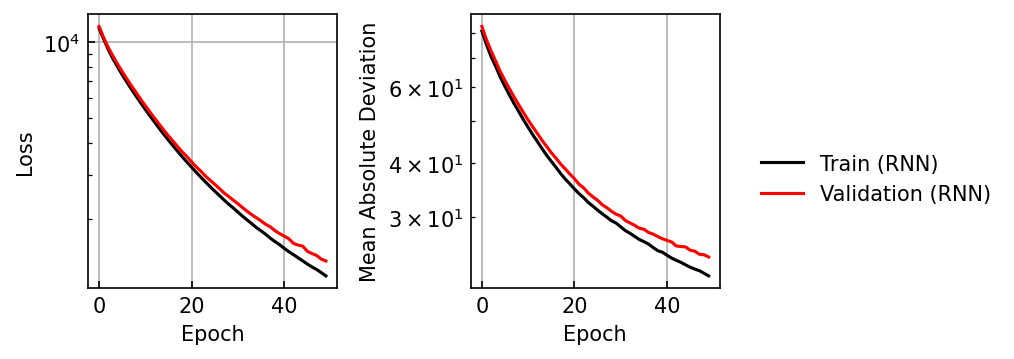

In [14]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(rnn_stats[0], color='black', label='Train (RNN)')
ax[0].plot(rnn_stats[2], color='red', label='Validation (RNN)')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(rnn_stats[1], color='black', label='Train (RNN)')
ax[1].plot(rnn_stats[3], color='red', label='Validation (RNN)')
ax[1].set(xlabel='Epoch', ylabel='Mean Absolute Deviation', yscale='log')

fig.legend(*ax[1].get_legend_handles_labels(), 
        loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

[Text(0, 0.5, 'Sunspots')]

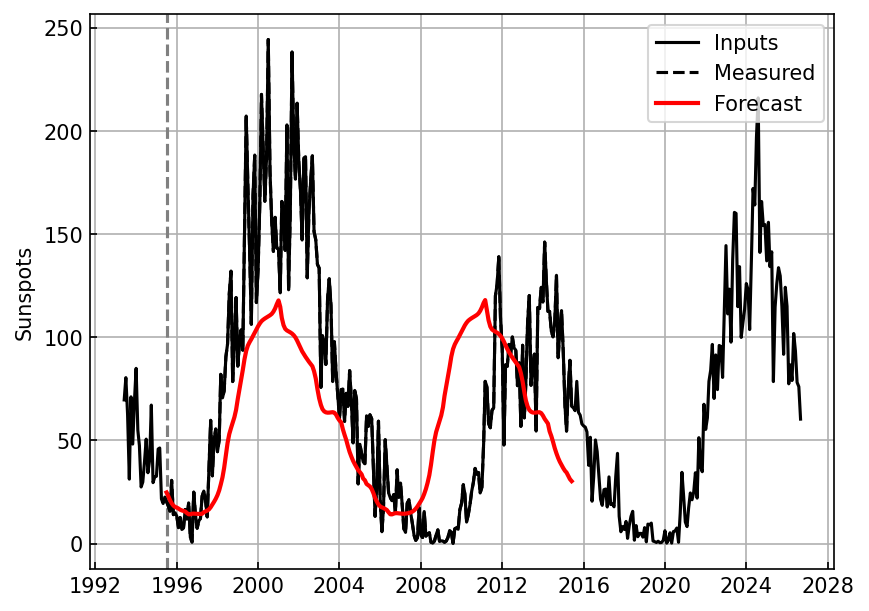

In [15]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]
forecast_len = 240
with torch.no_grad():
    x_in = torch.FloatTensor(x_in).to(device)
    y_rnn = []
    for ii in range(forecast_len):
        y_out = rnn_model(x_in[None])
        y_rnn.append(y_out.cpu().numpy()[0])

        x_in = torch.concat([x_in[1:], y_out])

    y_rnn = np.array(y_rnn)
    
ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_rnn)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_rnn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(ylabel='Sunspots')

## RNN forecasting with residual connections

A residual connection on RNN outputs is analagous to the discrete form of a differential equation
\begin{align*}
    y(t + \Delta t) &= y(t) + RNN(t) \, \Delta t \\
    \\
    \rightarrow RNN(t) &= \frac{y(t + \Delta t) - y(t)}{\Delta t} \approx \frac{d y}{dt}
\end{align*}

A continuous analogue which is both interesting and useful is [NeuralODE](https://arxiv.org/abs/1806.07366)

In [16]:
class Residual_Sequence_Forecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 128, num_layers=1, batch_first=True)
        self.linear = nn.Linear(128, 1)
        
    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)
        output = self.linear(output[:, -1])
        return x[:, -1] + output

rnn_model = Residual_Sequence_Forecast().to(device)
loss = nn.MSELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=1e-3)
rnn_model, rnn_stats = train(rnn_model, optimizer, loss, train_dataset, val_dataset, num_epochs=50)

  0%|          | 0/50 [00:00<?, ?it/s]

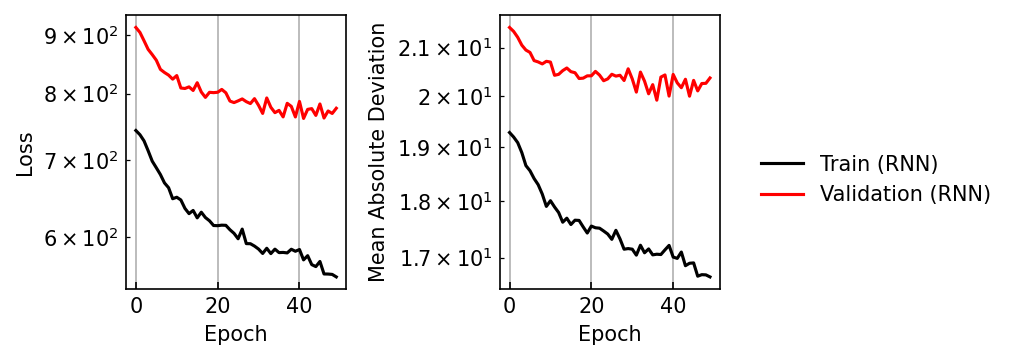

In [17]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(rnn_stats[0], color='black', label='Train (RNN)')
ax[0].plot(rnn_stats[2], color='red', label='Validation (RNN)')
ax[0].set(xlabel='Epoch', ylabel='Loss', yscale='log')

ax[1].plot(rnn_stats[1], color='black', label='Train (RNN)')
ax[1].plot(rnn_stats[3], color='red', label='Validation (RNN)')
ax[1].set(xlabel='Epoch', ylabel='Mean Absolute Deviation', yscale='log')

fig.legend(*ax[1].get_legend_handles_labels(), 
        loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

[Text(0, 0.5, 'Sunspots')]

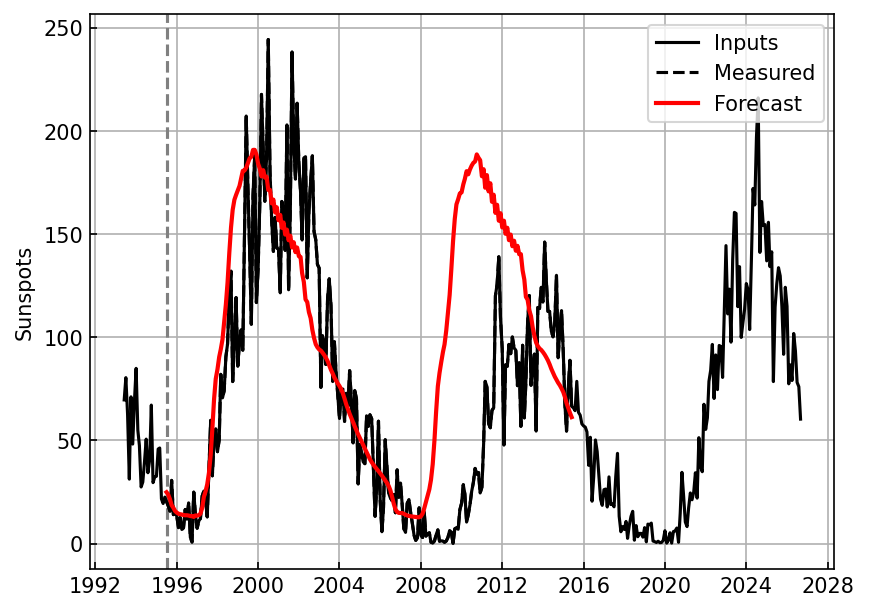

In [18]:
start_forecast_idx = test_dataset.seq_len
x_in, _ = test_dataset[0]
forecast_len = 240
with torch.no_grad():
    x_in = torch.FloatTensor(x_in).to(device)
    y_rnn = []
    for ii in range(forecast_len):
        y_out = rnn_model(x_in[None])
        y_rnn.append(y_out.cpu().numpy()[0])

        x_in = torch.concat([x_in[1:], y_out])

    y_rnn = np.array(y_rnn)

ax = plt.figure().gca()
ax.axvline(test_dataset.df.date.iloc[test_dataset.seq_len], color='grey', linestyle='--')
ax.plot(test_dataset.df.date, test_dataset.df.Sunspots, color='black', label='Inputs')

t = test_dataset.df.date.iloc[start_forecast_idx:start_forecast_idx + len(y_rnn)]
ax.plot(t, test_dataset.df.Sunspots[start_forecast_idx:start_forecast_idx+len(y_rnn)], 
        color='black', linestyle='--', label='Measured')
ax.plot(t, y_rnn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(ylabel='Sunspots')

## Echo State Networks

In [19]:
from scipy import sparse
from sklearn.linear_model import Ridge

def random_sparse_matrix(N, degree=3, spectral_radius=0.9):
    # Random symmetric, sparsely connected graph adjecency matrix
    edge_prob = degree / N
    A = np.random.rand(N, N) < edge_prob
    
    # Symmetrize the matrix
    A = np.triu(A)
    A = A + A.T

    # Convert to scipy sparse matrix
    A = sparse.csr_matrix(A.astype(float))

    # Compute spectral radius and rescale
    print('Rescaling reservoir', flush=True)
    max_eig = np.max(np.abs(sparse.linalg.eigs(A)[0]))

    A = A * spectral_radius / max_eig
    
    return A

class EchoStateNetwork:
    def __init__(self,
                 data_dim=1,
                 reservoir_dim=512,
                 spectral_radius=0.6,
                 avg_degree=3,
                 read_in_size=0.1,
                 l2_weight=1e-4,
                 noise=1e-3,
                 random_seed=42):
        self.data_dim = data_dim
        self.reservoir_dim = reservoir_dim
        self.spectral_radius = spectral_radius
        self.avg_degree = avg_degree
        self.l2_weight = l2_weight
        self.noise = noise

        # Initialize weights
        print('Initializing reservoir weights', flush=True)
        np.random.seed(random_seed)
        self.W_res = random_sparse_matrix(self.reservoir_dim, avg_degree, spectral_radius)

        # Initialize random input weights to the reservoir
        print('Initializing input weights')
        self.W_in = np.random.uniform(low=-read_in_size, high=read_in_size, size=[self.reservoir_dim, self.data_dim])

    def _step(self, input_state, hidden_state):
        """ Perform a reservoir update step
        """
        z = self.W_in @ input_state + self.W_res @ hidden_state
        noise = self.noise * (np.random.rand(*z.shape) - 0.5)
        return np.tanh(z) + noise

    def fit(self, X, transient=100):
        """ Fit the reservoir readout weights
            X is a sequence of size [N, d]
        """
        print('Starting to fit', flush=True)
        # Compute the hidden states at each element of the sequence
        N = X.shape[0]
        hidden_states = np.zeros([N, self.reservoir_dim])
        print('Computing hidden states', flush=True)
        for ii in range(1, N):
            hidden_states[ii, :] = self._step(X[ii-1], hidden_states[ii-1])


        print('Solving for readout weights', flush=True)
        inputs = hidden_states[transient:]
        targets = X[transient:]
        
        ridge = Ridge(alpha=self.l2_weight, fit_intercept=False).fit(inputs, targets)
        self.W_out = ridge.coef_

        # Save for continuation prediction
        self.last_out = X[-1]
        self.last_hidden = hidden_states[-1]
        
        return self
    
    def predict(self, N, input_state=None, hidden_state=None):
        """ Make a prediction given a new input
        """
        # Pick up from where we left off
        if input_state is None:
            input_state = self.last_out
        if hidden_state is None:
            hidden_state = self.last_hidden
        
        y = np.zeros([N, self.data_dim])
        for ii in range(N):
            hidden_state = self._step(input_state, hidden_state)
            y[ii] = self.W_out @ hidden_state
            input_state = y[ii]

        return y

Initializing reservoir weights
Rescaling reservoir
Initializing input weights
Starting to fit
Computing hidden states
Solving for readout weights


[(1950.0, 2030.0),
 Text(0.5, 0, 'Year'),
 (0.0, 300.0),
 Text(0, 0.5, 'Sunspots')]

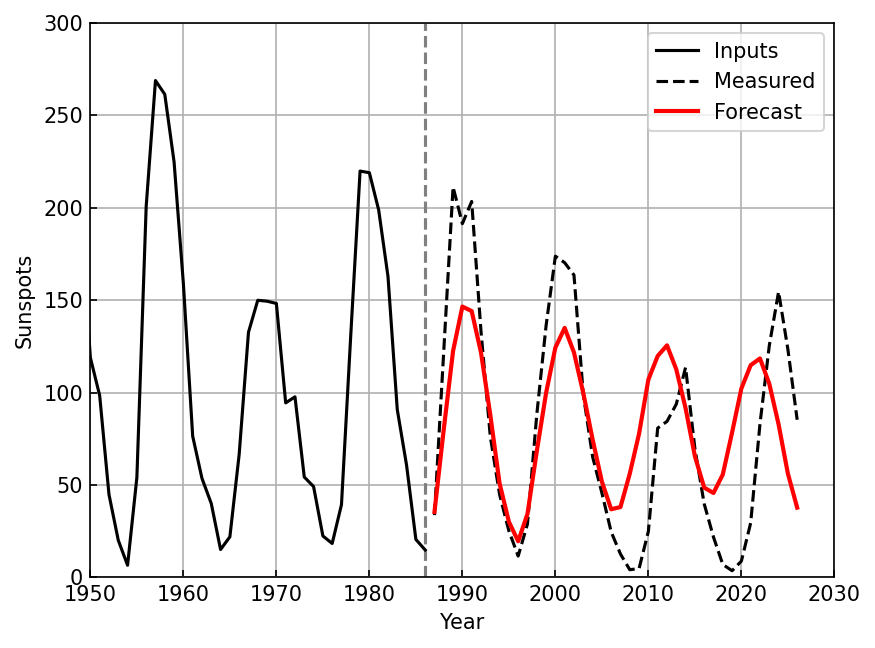

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

forecast_years = 40
df_train = year_df.iloc[:-forecast_years]
df_test = year_df.iloc[-forecast_years:]

x_train = df_train['Sunspots'].values[:, None]
x_test = df_test['Sunspots'].values[:, None]

model = EchoStateNetwork()
model.fit(scaler.fit_transform(x_train))

y_esn = scaler.inverse_transform(model.predict(len(x_test)))

ax = plt.figure().gca()
ax.axvline(df_train.Year.iloc[-1], color='grey', linestyle='--')
ax.plot(df_train.Year, df_train.Sunspots, color='black', label='Inputs')

ax.plot(df_test.Year, df_test.Sunspots, color='black', linestyle='--', label='Measured')
ax.plot(df_test.Year, y_esn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

ax.set(
    xlim=[1950, 2030],
    xlabel='Year',
    ylim=[0, 300],
    ylabel='Sunspots',
)

Initializing reservoir weights
Rescaling reservoir
Initializing input weights
Starting to fit
Computing hidden states
Solving for readout weights


[(-7305.0, 21915.0), Text(0, 0.5, 'Sunspots')]

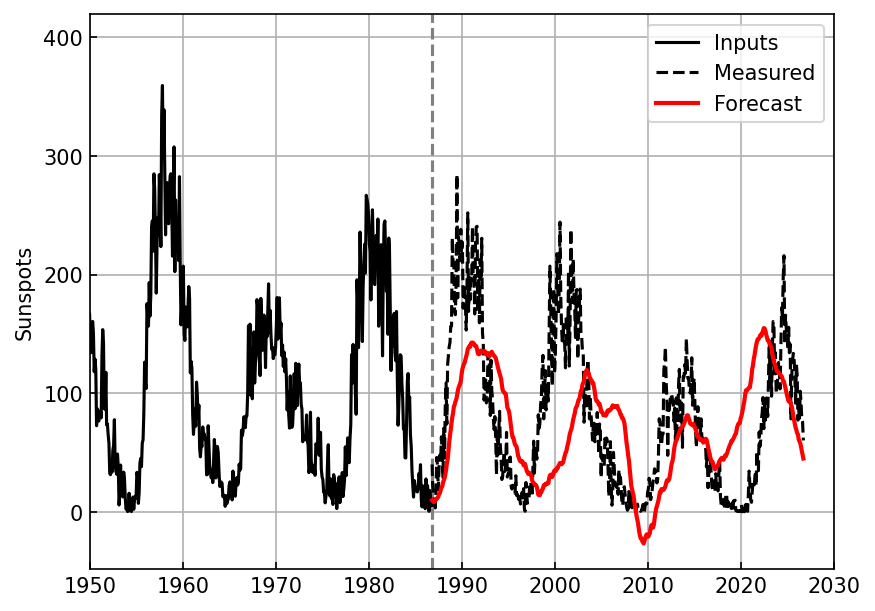

In [24]:
from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter

scaler = StandardScaler()

forecast_months = forecast_years * 12
x_train = df['Sunspots'].values[:-forecast_months, None]
x_train = savgol_filter(x_train, window_length=12, polyorder=1, axis=0)
x_test = df['Sunspots'].values[-forecast_months:, None]

model = EchoStateNetwork(reservoir_dim=1500)
model.fit(scaler.fit_transform(x_train))

y_esn = scaler.inverse_transform(model.predict(len(x_test)))

ax = plt.figure().gca()
ax.axvline(df.date.iloc[-forecast_months], color='grey', linestyle='--')
ax.plot(df.date.iloc[:-forecast_months], 
        df.Sunspots.iloc[:-forecast_months], 
        color='black', label='Inputs')

ax.plot(df.date.iloc[-forecast_months:], df.Sunspots.iloc[-forecast_months:], color='black', linestyle='--', label='Measured')
ax.plot(df.date.iloc[-forecast_months:], y_esn, color='red', linewidth=2, label='Forecast')
ax.legend(loc='upper right')

import datetime
ax.set(
    xlim=[datetime.date(1950, 1, 1), datetime.date(2030, 1, 1)],
    ylabel='Sunspots'
)